# 00 · Ler e validar os dados da darknet

**Série de análises do Holoscope — notebook 0 de 6 (base para todos os outros)**

Antes de qualquer gráfico bonito, precisamos responder a perguntas chatas, mas decisivas:
*quais arquivos existem? de que sensor e de que dia é cada um? em que unidade está o tempo?
como um IP aparece no arquivo? tem lixo misturado?* Erros aqui contaminam tudo o que vem depois.

**Ao final deste notebook você saberá:**

1. listar os arquivos e montar o **inventário sensor × dia** (e achar buracos na coleta);
2. abrir **um** parquet "cru" e entender cada coluna;
3. carregar vários sensores e dias num único `DataFrame` com `carregar_holoscope`;
4. remover tráfego que **não** é da internet (origens privadas);
5. processar dados grandes **arquivo por arquivo**, sem estourar a memória.

> 💡 Os notebooks rodam com **dados fictícios** gerados no mesmo formato dos reais
> (`gerar_sintetico_real.py`). Para usar os dados reais, troque **só** a variável `PASTA`.

## Relembrando: o que é uma darknet?

Uma **darknet** (ou *telescópio de rede*) é um bloco de endereços IP **que não hospeda nenhum serviço**.
Ninguém deveria mandar nada para lá — então **tudo** o que chega é, por definição, suspeito ou acidental:

| O que chega | Por quê | Como aparece |
|---|---|---|
| **Varreduras** (*scans*) | alguém testando a internet inteira atrás de portas abertas | pacotes TCP com flag **SYN** (`S`), UDP ou ICMP |
| **Backscatter** | um servidor sob ataque DDoS *responde* a endereços forjados — alguns caem na darknet | TCP **SYN-ACK** (`SA`) ou **RST** (`R`, `RA`) |
| **Configuração errada** | equipamentos mal configurados | variado |

O Holoscope tem **vários sensores** (Brasil, Itália, nuvem). Cada sensor observa um pedaço de endereços.
A pergunta da série é: **o que os sensores veem em comum, e quando?**

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# A pasta raiz da série (onde estão os .py). Funciona tanto na raiz quanto em solucoes/.
RAIZ = os.path.abspath("..") if os.path.basename(os.getcwd()) == "solucoes" else os.getcwd()
sys.path.insert(0, RAIZ)
import holoscope_io as hio
import holoscope_ana as ha
ha.estilo()

# >>> Para usar os DADOS REAIS, troque só esta linha pela pasta dos parquet <<<
PASTA = os.path.join(RAIZ, "dados_sinteticos")
if not os.path.isdir(PASTA):   # primeira vez: gera os dados fictícios (~20 s)
    import subprocess
    subprocess.run([sys.executable, os.path.join(RAIZ, "gerar_sintetico_real.py"), "--saida", PASTA], check=True)

## 1. Inventário: que arquivos existem?

Os dados vêm em **um parquet por sensor e por dia**, e o **arquivo não tem coluna de sensor**: o sensor
e o dia estão no **nome** do arquivo, por exemplo `polimi-worker-01-2026-09-03.parquet`.

`hio.inventario(PASTA)` percorre a pasta e **não lê os dados**: só o nome e o rodapé (metadados) de cada
arquivo. É instantâneo mesmo com centenas de GB.

In [2]:
inv = hio.inventario(PASTA)
print(f"{len(inv)} arquivos | {inv['sensor'].nunique()} sensores | {inv['site'].nunique()} sites | "
      f"{inv['dia'].min()} a {inv['dia'].max()} | {inv['linhas'].sum():,} linhas | {inv['mb'].sum():,.0f} MB")
inv.drop(columns="caminho").head(8)   # a coluna caminho tem o arquivo de cada linha

83 arquivos | 6 sensores | 5 sites | 2026-09-01 a 2026-09-14 | 2,059,894 linhas | 70 MB


,sensor,site,dia,mb,linhas
0,azure-worker-00,azure,2026-09-01,0.562824,16838
1,azure-worker-00,azure,2026-09-02,0.698607,20922
2,azure-worker-00,azure,2026-09-03,0.641377,19477
3,azure-worker-00,azure,2026-09-04,0.649622,19960
4,azure-worker-00,azure,2026-09-05,0.767437,23263
5,azure-worker-00,azure,2026-09-07,0.643028,19554
6,azure-worker-00,azure,2026-09-08,0.620948,18817
7,azure-worker-00,azure,2026-09-09,0.731983,21543


Repare nas colunas **`sensor`** e **`site`**. Um *site* (instituição) pode ter vários *workers*
(ex.: `polimi-worker-00` e `polimi-worker-01`). Na série, a unidade padrão de análise é o **worker**;
quando fizer sentido, somamos por site (`unidade="site"`).

### Como o leitor reconhece o nome dos arquivos

O leitor tenta, em ordem, três **expressões regulares** (veja `hio.PADROES`):

| Organização | Exemplo |
|---|---|
| tudo na mesma pasta | `ufes-worker-00-2026-09-01.parquet` |
| uma subpasta por sensor | `ufes-worker-00/2026-09-01.parquet` |
| estilo Hive/Spark | `sensor=ufes-worker-00/dia=2026-09-01/part-0.parquet` |

Se os dados reais vierem com outro nome, **passe seu próprio padrão** (ver desafio no fim).

### A matriz sensor × dia

Uma tabela com sensores nas linhas, dias nas colunas e o nº de pacotes nas células.
É o **primeiro gráfico** a fazer com dados novos: mostra buracos e dias estranhos de cara.

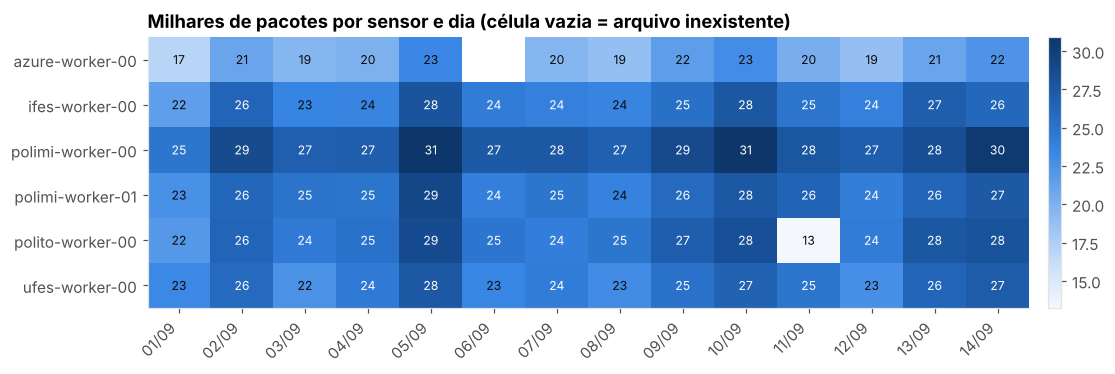

In [3]:
M = hio.matriz_inventario(inv, "linhas") / 1000
fig, ax = plt.subplots(figsize=(11, 3.2))
ha.heatmap(M.rename(columns=lambda d: d.strftime("%d/%m")), ax=ax, fmt="{:.0f}",
           titulo="Milhares de pacotes por sensor e dia (célula vazia = arquivo inexistente)")
plt.show()

**Como ler:** cada célula é um arquivo. Observe duas coisas:

* há uma **célula vazia** → aquele arquivo **não existe**. Isso é diferente de "zero pacotes":
  o sensor estava fora do ar (ou o arquivo se perdeu). Em análises de volume, **dia sem arquivo deve virar
  `NaN`, nunca 0**, senão você "inventa" uma queda de tráfego;
* há uma célula **bem mais clara** que as vizinhas → provável **queda parcial** da coleta. Vamos confirmar
  isso no notebook 03 olhando a série por hora.

> ⚠️ **Armadilha:** comparar volumes entre sensores sem antes olhar esta matriz.

### ✏️ TODO 1 — Quais dias faltam em cada sensor?

Monte um dicionário `resp_1 = {sensor: [dias faltando]}` com **apenas** os sensores que têm algum dia
faltando. Considere o período completo do inventário (do primeiro ao último dia de qualquer sensor).

<details><summary><b>Dica</b> (clique)</summary>

`pd.date_range(inicio, fim, freq="D").date` gera todos os dias. Para cada sensor, compare com
`inv.loc[inv.sensor == s, "dia"]` usando `set`.

</details>

In [4]:
resp_1 = None   # TODO

In [5]:
# Verificação (não precisa mexer)
if resp_1 is None:
    print("⏳ TODO 1 ainda não resolvido")
else:
    assert isinstance(resp_1, dict) and len(resp_1) >= 1, "deveria haver pelo menos um sensor com buraco"
    assert all(len(v) > 0 for v in resp_1.values()), "liste só sensores com dias faltando"
    print("✅ TODO 1 ok:", resp_1)

⏳ TODO 1 ainda não resolvido


## 2. Abrindo UM arquivo "cru"

Antes de usar o leitor pronto, vale olhar um arquivo do jeito que ele está no disco, com `pyarrow`.
Assim você entende **o que o leitor faz por você**.

In [6]:
import pyarrow.parquet as pq

arq = inv.loc[inv["sensor"] == "ufes-worker-00", "caminho"].iloc[0]
pf = pq.ParquetFile(arq)
print(pf.schema_arrow)
print(f"\n{pf.metadata.num_rows:,} linhas em {pf.metadata.num_row_groups} row groups")

timestamp: int64
src_ip: uint32
dst_ip: uint32
src_port: uint16
dst_port: uint16
transport_proto: dictionary<values=string, indices=int32, ordered=0>
app_proto: dictionary<values=string, indices=int32, ordered=0>
ttl: uint8
ip_id: uint16
ip_df: bool
window: uint16
pkt_len: uint16
tcp_flags: uint8
mss: uint32
wscale: uint32
has_sack: bool
has_ts: bool
tcp_options_ordered: dictionary<values=string, indices=int32, ordered=0>
flow_hash: uint64
src_asn: struct<asn: uint32, network: dictionary<values=string, indices=int32, ordered=0>, organization_name: (... 53 chars omitted)
  child 0, asn: uint32
  child 1, network: dictionary<values=string, indices=int32, ordered=0>
  child 2, organization_name: dictionary<values=string, indices=int32, ordered=0>
src_geo: struct<continent_name: dictionary<values=string, indices=int32, ordered=0>, country_iso_code: dictio (... 157 chars omitted)
  child 0, continent_name: dictionary<values=string, indices=int32, ordered=0>
  child 1, country_iso_code: dict

### Dicionário das colunas

| Coluna | Tipo | O que é |
|---|---|---|
| `timestamp` | int64 | instante de chegada, em **nanossegundos** desde 1970-01-01 **UTC** |
| `src_ip`, `dst_ip` | uint32 | IP de origem / destino como **número inteiro** (ver abaixo) |
| `src_port`, `dst_port` | uint16 | portas; `dst_port` diz **qual serviço** foi procurado (22 = SSH, 23 = Telnet…) |
| `transport_proto` | texto | TCP, UDP ou ICMP |
| `app_proto` | texto | serviço provável, deduzido da porta (HTTP, SSH, SNMP…) |
| `tcp_flags` | uint8 | flags TCP como **bits** (SYN = 2, ACK = 16…) |
| `ttl` | uint8 | *time to live*: diminui 1 a cada roteador; ajuda a estimar a distância |
| `ip_id`, `window`, `mss`, `wscale`, `has_sack`, `has_ts`, `tcp_options_ordered`, `ip_df`, `pkt_len` | | detalhes do cabeçalho — servem de **impressão digital** da ferramenta (notebook 04) |
| `flow_hash` | uint64 | identificador do fluxo (mesma origem, destino e portas) |
| `src_asn` | **struct** | `{asn, network, organization_name}`: a **rede/empresa** dona do IP de origem |
| `src_geo` | **struct** | `{continent_name, country_iso_code, country_name, location{lat, lon}}` |

Um *struct* é uma coluna que contém **várias subcolunas**. O leitor "achata" isso para `asn`, `asn_org`, `pais`…

In [7]:
crua = pq.read_table(arq).slice(0, 3).to_pandas()
crua[["timestamp", "src_ip", "dst_ip", "dst_port", "tcp_flags", "src_asn"]]

,timestamp,src_ip,dst_ip,dst_port,tcp_flags,src_asn
0,1788220810787767942,887696972,3323071011,56532,18,"{'asn': 64721, 'network': '52.233.0.0/16', 'or..."
1,1788220933502926355,515320917,3323071075,445,2,"{'asn': 64779, 'network': '30.183.0.0/16', 'or..."
2,1788220941586030354,515320917,3323071157,23,194,"{'asn': 64779, 'network': '30.183.0.0/16', 'or..."


### Por que *nanossegundos*? E como saber?

O `timestamp` é só um número enorme. A unidade **não está escrita** em lugar nenhum do arquivo. O truque:
converta com cada unidade possível e veja qual dá uma data plausível.

In [8]:
t = int(crua["timestamp"].iloc[0])
for unidade in ["s", "ms", "us", "ns"]:
    try:
        print(f"{unidade:>3}: {pd.to_datetime(t, unit=unidade, utc=True)}")
    except Exception as e:
        print(f"{unidade:>3}: impossível ({type(e).__name__})")

  s: 56666463635-06-29 10:12:22+00:00
 ms: 56668431-08-31 20:36:07.942000+00:00
 us: 58636-06-18 02:59:47.767942+00:00
 ns: 2026-09-01 00:00:10.787767942+00:00


Só **`ns`** dá uma data que faz sentido. E o fuso? Epoch é, por definição, contado em **UTC**;
por isso sempre convertemos com `utc=True`. **Nunca** misture com horário local sem querer — no notebook 03
faremos isso *de propósito*, para entender ciclos diários.

### IP como número

Um IPv4 `a.b.c.d` é guardado como `a·2²⁴ + b·2¹⁶ + c·2⁸ + d`. Números ocupam menos memória e são mais
rápidos para agrupar. Converta para texto **só para mostrar**:

In [9]:
ips = crua["src_ip"]
pd.DataFrame({"inteiro": ips, "texto": hio.ip_texto(ips), "rede /24": hio.rede_texto(hio.prefixo(ips, 24))})

,inteiro,texto,rede /24
0,887696972,52.233.46.76,52.233.46.0/24
1,515320917,30.183.44.85,30.183.44.0/24
2,515320917,30.183.44.85,30.183.44.0/24


### ✏️ TODO 2 — Converter um IP na mão

Sem usar `hio.ip_texto`, converta o inteiro `3232235777` para texto `"a.b.c.d"` usando deslocamento
de bits (`>>`) e máscara (`& 255`). Guarde em `resp_2`.

<details><summary><b>Dica</b> (clique)</summary>

`a = (x >> 24) & 255`, `b = (x >> 16) & 255`, e assim por diante.

</details>

In [10]:
x = 3232235777
resp_2 = None   # TODO

In [11]:
# Verificação (não precisa mexer)
if resp_2 is None:
    print("⏳ TODO 2 ainda não resolvido")
else:
    assert resp_2 == hio.ip_texto(pd.Series([3232235777])).iloc[0], "confira a ordem dos deslocamentos"
    print("✅ TODO 2 ok:", resp_2, "— é um endereço PRIVADO (192.168.0.0/16). Veja a seção 4!")

⏳ TODO 2 ainda não resolvido


### Flags TCP como bits

Cada flag é um bit: `F=1, S=2, R=4, P=8, A=16, U=32, E=64, C=128`. Um SYN-ACK é `2 + 16 = 18`.
`hio.flags_texto` traduz:

In [12]:
exemplos = pd.Series([0, 2, 18, 4, 20, 194])
pd.DataFrame({"bits": exemplos, "texto": hio.flags_texto(exemplos),
              "significado": ["não-TCP (UDP/ICMP)", "SYN: 'tem alguém aí?' (varredura)",
                              "SYN-ACK: resposta (backscatter)", "RST: recusa (backscatter)",
                              "RST-ACK (backscatter)", "SYN com ECN (pilha de SO moderna)"]})

,bits,texto,significado
0,0,,não-TCP (UDP/ICMP)
1,2,S,SYN: 'tem alguém aí?' (varredura)
2,18,SA,SYN-ACK: resposta (backscatter)
3,4,R,RST: recusa (backscatter)
4,20,RA,RST-ACK (backscatter)
5,194,SEC,SYN com ECN (pilha de SO moderna)


## 3. Carregando vários sensores e dias

`hio.carregar_holoscope` faz tudo o que vimos: lê os arquivos selecionados, converte o tempo, cria as colunas
`sensor` e `site`, achata os structs e junta tudo.

Parâmetros importantes:

* `sensores=[...]`, `inicio=`, `fim=` → **leia só o que precisa** (os dados reais são grandes!);
* `extras=` → grupos de colunas além das básicas: `"asn"`, `"geo"`, `"app"`, `"fingerprint"`, `"fluxo"`;
* `unidade="worker"` ou `"site"`.

In [13]:
df = hio.carregar_holoscope(PASTA, extras=("asn",))
df.head()

83 arquivos | 6 sensores (worker) | 2026-09-01 a 2026-09-14 | 2,024,894 pacotes | 67 MB na memória
origens reservadas/privadas descartadas: 35,000


,ts,sensor,site,src_ip,dst_ip,src_port,dst_port,transport_proto,tcp_flags,asn,asn_rede,asn_org
0,2026-09-01 00:00:05.337532866+00:00,ifes-worker-00,ifes,577773216,3323073570,60749,2323,TCP,2,64827,34.112.0.0/16,Broadband Exemplo 315 (IR)
1,2026-09-01 00:00:07.290313692+00:00,ifes-worker-00,ifes,577773216,3323073781,60749,8080,TCP,2,64827,34.112.0.0/16,Broadband Exemplo 315 (IR)
2,2026-09-01 00:00:10.787767942+00:00,ufes-worker-00,ufes,887696972,3323071011,25,56532,TCP,18,64721,52.233.0.0/16,Hosting Exemplo 209 (CN)
3,2026-09-01 00:00:15.430011343+00:00,polito-worker-00,polito,2943432484,3323078811,443,18715,TCP,4,64845,175.113.0.0/16,Datacenter Exemplo 333 (US)
4,2026-09-01 00:00:22.034344489+00:00,polimi-worker-01,polimi,3703451122,3323076431,2808,1433,TCP,2,64512,220.190.0.0/16,Cloud Exemplo 000 (IN)


In [14]:
df.dtypes.to_frame("tipo").T

,ts,sensor,site,src_ip,dst_ip,src_port,dst_port,transport_proto,tcp_flags,asn,asn_rede,asn_org
tipo,"datetime64[ns, UTC]",category,category,uint32,uint32,uint16,uint16,category,uint8,UInt32,category,category


**Memória:** cada coluna extra custa. Compare:

In [15]:
def mb(d):
    return d.memory_usage(deep=True).sum() / 1e6

pequeno = hio.carregar_holoscope(inv, sensores=["ufes-worker-00"], inicio="2026-09-01", fim="2026-09-03",
                                 extras=(), verbose=False)
grande = hio.carregar_holoscope(inv, sensores=["ufes-worker-00"], inicio="2026-09-01", fim="2026-09-03",
                                extras=("asn", "geo", "app", "fingerprint", "fluxo"), verbose=False)
print(f"só básicas: {mb(pequeno):.1f} MB   |   com todos os extras: {mb(grande):.1f} MB   "
      f"({len(pequeno):,} pacotes)")

só básicas: 1.7 MB   |   com todos os extras: 5.8 MB   (71,559 pacotes)


> ⚠️ **Nos dados reais**, o struct `src_asn` traz um dicionário enorme de nomes de organização repetido em cada
> *row group*. Por isso o leitor lê esses arquivos **um row group por vez** (o pico de memória caiu de ~1,8 GB
> para ~300 MB num arquivo real de teste). Mesmo assim: **só peça `extras` que vai usar**.

### ✏️ TODO 3 — Carregar um recorte

Carregue em `resp_3` **só os sensores brasileiros** (`ufes-worker-00` e `ifes-worker-00`), de **03/09 a 05/09/2026**,
com as colunas extras de **geolocalização**. Depois, mostre os 5 países com mais pacotes.

<details><summary><b>Dica</b> (clique)</summary>

`hio.carregar_holoscope(inv, sensores=[...], inicio="2026-09-03", fim="2026-09-05", extras=("geo",))`
e depois `resp_3["pais"].value_counts().head()`.

</details>

In [16]:
resp_3 = None   # TODO

In [17]:
# Verificação (não precisa mexer)
if resp_3 is None:
    print("⏳ TODO 3 ainda não resolvido")
else:
    assert set(resp_3["sensor"].unique()) == {"ufes-worker-00", "ifes-worker-00"}
    dias = resp_3["ts"].dt.date
    assert str(dias.min()) == "2026-09-03" and str(dias.max()) == "2026-09-05", "confira inicio/fim"
    assert "pais" in resp_3.columns, "faltou extras=('geo',)"
    print("✅ TODO 3 ok:", f"{len(resp_3):,} pacotes")

⏳ TODO 3 ainda não resolvido


### Worker ou site?

Com `unidade="site"`, os workers de uma mesma instituição viram **um** sensor:

In [18]:
por_site = hio.carregar_holoscope(inv, extras=(), unidade="site", verbose=False)
tab = df.groupby(["site", "sensor"], observed=True).size().rename("pacotes (worker)").reset_index()
tab["pacotes (site)"] = tab["site"].map(por_site["sensor"].value_counts())
tab

,site,sensor,pacotes (worker),pacotes (site)
0,azure,azure-worker-00,265334,265334
1,ifes,ifes-worker-00,349127,349127
2,polimi,polimi-worker-00,358009,715773
3,polimi,polimi-worker-01,357764,715773
4,polito,polito-worker-00,348210,348210
5,ufes,ufes-worker-00,346450,346450


## 4. Tráfego que **não** é da darknet

Endereços **privados** (`10.0.0.0/8`, `172.16.0.0/12`, `192.168.0.0/16`…) não circulam na internet.
Se aparecem como **origem** num sensor, o pacote veio da **rede local** do sensor (gerência, monitoração)
e **não é** uma varredura. Por padrão o leitor os descarta (`remover_reservados=True`) e informa quantos foram.

Vamos olhar o que seria descartado:

In [19]:
bruto = hio.carregar_holoscope(inv, sensores=["polimi-worker-00"], inicio="2026-09-01", fim="2026-09-01",
                               extras=("app",), remover_reservados=False, verbose=False)
priv = bruto[hio.eh_reservado(bruto["src_ip"].values)]
print(f"{len(priv):,} de {len(bruto):,} pacotes ({len(priv)/len(bruto):.1%}) vêm de origens privadas")
(priv.assign(origem=hio.ip_texto(priv["src_ip"]), destino=hio.ip_texto(priv["dst_ip"]))
     .groupby(["origem", "destino", "transport_proto", "dst_port", "app_proto"], observed=True).size()
     .rename("pacotes").reset_index())

2,515 de 24,777 pacotes (10.2%) vêm de origens privadas


,origem,destino,transport_proto,dst_port,app_proto,pacotes
0,10.79.0.116,198.18.30.6,UDP,161,SNMP,868
1,10.79.0.117,198.18.30.6,UDP,161,SNMP,812
2,10.79.1.17,198.18.30.6,UDP,161,SNMP,835


São consultas **SNMP** (porta UDP 161, usada para monitorar equipamentos) de 3 máquinas internas
para **um único** endereço. Isso é a rede do sensor conversando com ele mesmo — se entrasse nas análises,
essas 3 origens pareceriam "os maiores atacantes" do sensor!

> 📌 Foi exatamente isso que encontramos num arquivo **real** de teste: 100% SNMP de `10.79.0.0/16`.
> Sempre rode `hio.validar` e olhe a fração de origens reservadas.

In [20]:
hio.validar(bruto);

24,777 pacotes | colunas: ['ts', 'sensor', 'site', 'src_ip', 'dst_ip', 'src_port', 'dst_port', 'transport_proto', 'tcp_flags', 'app_proto']
[AVISO] 10.2% das origens são privadas/reservadas
[OK]    prefixos /24 de destino por sensor: polimi-worker-00=1
[OK]    1 sensores: ['polimi-worker-00']
=>  VÁLIDO


In [21]:
hio.validar(df);

2,024,894 pacotes | colunas: ['ts', 'sensor', 'site', 'src_ip', 'dst_ip', 'src_port', 'dst_port', 'transport_proto', 'tcp_flags', 'asn', 'asn_rede', 'asn_org']
[OK]    prefixos /24 de destino por sensor: azure-worker-00=1, ifes-worker-00=1, polimi-worker-00=1, polimi-worker-01=1, polito-worker-00=1, ufes-worker-00=1
[OK]    0.0% dos pacotes sem ASN
[OK]    6 sensores: ['azure-worker-00', 'ifes-worker-00', 'polimi-worker-00', 'polimi-worker-01', 'polito-worker-00', 'ufes-worker-00']
=>  VÁLIDO


## 5. Dados grandes: um arquivo por vez

Com os dados reais (meses × sensores), talvez **não caiba tudo na memória**. A saída é a estratégia
*dividir e conquistar*: ler **um arquivo (sensor, dia)**, calcular algo pequeno, guardar só o resultado e
passar ao próximo. É isso que `hio.agregar_por_arquivo(fonte, func)` faz.

Exemplo: pacotes, IPs distintos e portas distintas por sensor e dia.

In [22]:
def resumo_do_dia(d):
    return pd.DataFrame({"pacotes": [len(d)],
                         "ips": [d["src_ip"].nunique()],
                         "portas": [d["dst_port"].nunique()]})

resumo = hio.agregar_por_arquivo(inv, resumo_do_dia, extras=())
resumo.head()

  20/83 arquivos processados


  40/83 arquivos processados


  60/83 arquivos processados


  80/83 arquivos processados
  83/83 arquivos processados


,sensor,dia,pacotes,ips,portas
0,azure-worker-00,2026-09-01,16838,1617,1003
1,azure-worker-00,2026-09-02,20922,1745,2822
2,azure-worker-00,2026-09-03,19477,1730,935
3,azure-worker-00,2026-09-04,19960,1717,941
4,azure-worker-00,2026-09-05,23263,1740,4535


> ⚠️ **Armadilha:** "IPs distintos" **não soma** entre dias. Um IP visto na segunda e na terça conta 1 vez
> em cada dia, mas 1 vez só na semana. Por isso agregações como `nunique` precisam ser pensadas: às vezes
> é preciso guardar o **conjunto** (ou um resumo dele) por arquivo e unir depois.

### ✏️ TODO 4 — Pacotes SYN por sensor e dia, sem carregar tudo

Use `hio.agregar_por_arquivo` para contar, em cada (sensor, dia), quantos pacotes têm `tcp_flags == 2`
(SYN puro). Guarde a tabela longa em `resp_4` (colunas `sensor`, `dia`, `syn`) e depois transforme em
tabela larga sensor × dia com `pivot`.

<details><summary><b>Dica</b> (clique)</summary>

A função pode devolver `pd.DataFrame({"syn": [(d["tcp_flags"] == 2).sum()]})`.

</details>

In [23]:
resp_4 = None   # TODO

In [24]:
# Verificação (não precisa mexer)
if resp_4 is None:
    print("⏳ TODO 4 ainda não resolvido")
else:
    assert {"sensor", "dia", "syn"} <= set(resp_4.columns)
    assert len(resp_4) == len(inv), "deveria haver uma linha por arquivo"
    assert resp_4["syn"].sum() == (df["tcp_flags"] == 2).sum(), "o total não bate com o DataFrame completo"
    print("✅ TODO 4 ok")

⏳ TODO 4 ainda não resolvido


## Resumo

* O sensor e o dia vêm do **nome do arquivo** → `hio.inventario`.
* `timestamp` está em **ns UTC**; IPs são **uint32**; flags são **bits**; ASN e país vêm em **structs**.
* `hio.carregar_holoscope(...)` devolve um `DataFrame` padronizado; peça só os `extras` necessários.
* **Origens privadas** não são darknet → descartadas por padrão; sempre rode `hio.validar`.
* Para dados grandes, `hio.agregar_por_arquivo`.

## Desafios (sem solução)

1. **Outro formato de nome.** Crie uma cópia de 2 arquivos renomeados para `20260901_ufes-worker-00.parquet`
   (data antes do sensor). Escreva um padrão em `padroes=[...]` que funcione.
2. **Pasta Hive.** Reorganize alguns arquivos como `sensor=X/dia=AAAA-MM-DD/part-0.parquet` e confira que
   o inventário continua igual.
3. **DuckDB.** Instale `duckdb` e conte pacotes por sensor com uma consulta SQL direto nos arquivos
   (`read_parquet('pasta/*.parquet', filename=true)`), extraindo o sensor do nome com `regexp_extract`.
   Compare o tempo com o pandas.
4. **Validação extra.** Acrescente ao `hio.validar` uma checagem: todo `dst_ip` de um sensor deveria cair
   no(s) bloco(s) daquele sensor. Como descobrir o bloco de cada sensor só pelos dados?